<a href="https://colab.research.google.com/github/pajola/secai-course/blob/main/module-01-adversarial-ml/04_membership_inference.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab" width="150"></a>

# 4 · Membership Inference — what a model leaks about its training data

**SecAI course · Adversarial Machine Learning, part 4**

So far the attacker wanted to change the model's *behaviour*. Here the attacker wants **information**: *was this specific record used to train the model?*
That is a privacy breach on its own (a model trained on patients of a clinic, on users of a service, on a copyright-protected corpus) and the standard building block for auditing memorisation in LLMs.

| | Membership inference attack (MIA) |
|---|---|
| **Goal** | given a record $x$ (and its label), decide **member** (in the training set) vs **non-member** |
| **Knowledge** | black-box: query the model, get confidence scores. Optionally: data from the same distribution to train *shadow* models |
| **Capability** | none — the attacker only observes |

Root cause: **overfitting**. A model behaves slightly differently on data it has seen (lower loss, higher confidence) than on data it has not.

*Dataset note:* MNIST is so easy that even a model trained on 2 000 digits reaches 96% on unseen ones — there is almost nothing to leak. We therefore use **Fashion-MNIST** (same format, harder), a small training set and a fully-connected network: the recipe for memorisation.

In [ ]:
# Setup — on Google Colab, fetch the course helper module (all other packages are preinstalled).
import os, sys, urllib.request
if "google.colab" in sys.modules and not os.path.exists("secai_utils.py"):
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/pajola/secai-course/main/module-01-adversarial-ml/secai_utils.py", "secai_utils.py")

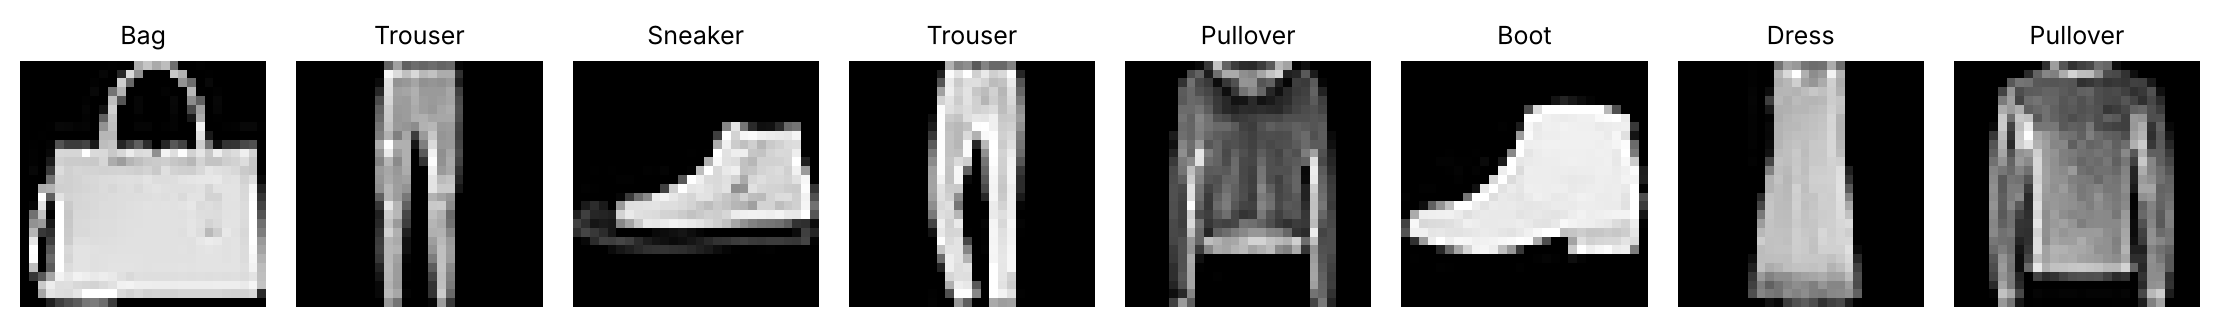

victim: train accuracy = 1.000   test accuracy = 0.778   (generalisation gap = 0.222)


In [1]:
import numpy as np, torch, torch.nn.functional as F, matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.ensemble import GradientBoostingClassifier
from scipy.stats import norm
from secai_utils import *

seed_everything(0)
x_all, y_all, x_test, y_test = load_fashion_mnist(n_train=20_000, n_test=2_000)
show_images(x_all[:8], titles=[FASHION_CLASSES[int(t)] for t in y_all[:8]])

# The victim is trained on a *small* dataset for *many* epochs — the typical recipe for memorisation.
N_MEMBERS, EPOCHS = 500, 100
x_mem, y_mem = x_all[:N_MEMBERS], y_all[:N_MEMBERS]              # members
x_non, y_non = x_test[:N_MEMBERS], y_test[:N_MEMBERS]            # non-members (never seen)
x_attacker, y_attacker = x_all[N_MEMBERS:], y_all[N_MEMBERS:]    # data the *attacker* owns, from the same distribution

def victim_recipe(x, y, seed=0):
    seed_everything(seed); return train(MLP(), x, y, epochs=EPOCHS, verbose=False)

victim = victim_recipe(x_mem, y_mem)
print(f"victim: train accuracy = {accuracy(victim, x_mem, y_mem):.3f}   test accuracy = {accuracy(victim, x_non, y_non):.3f}   (generalisation gap = {accuracy(victim, x_mem, y_mem) - accuracy(victim, x_non, y_non):.3f})")

## 4.1 The signal: members have lower loss

Query the model on members and non-members and look at the per-sample loss $-\log p_y(x)$.

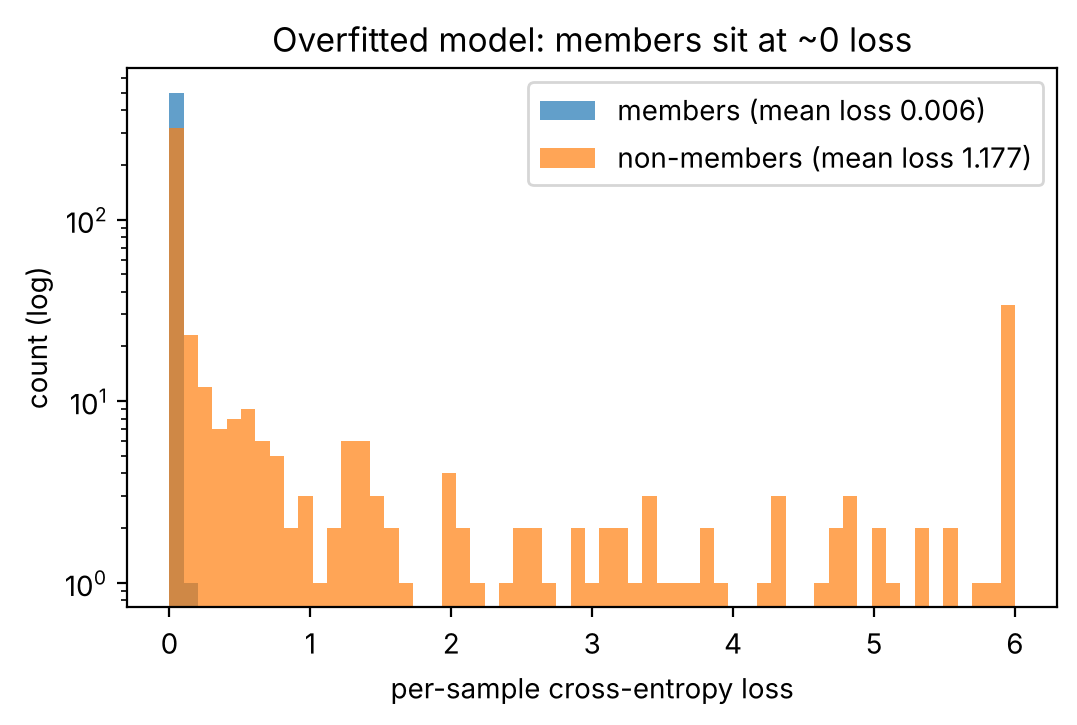

In [2]:
def per_sample_loss(model, x, y):
    return F.cross_entropy(predict(model, x), y, reduction="none").numpy()

loss_mem, loss_non = per_sample_loss(victim, x_mem, y_mem), per_sample_loss(victim, x_non, y_non)

plt.figure(figsize=(6, 3.5))
bins = np.linspace(0, 6, 60)
plt.hist(np.clip(loss_mem, 0, 6), bins, alpha=.7, label=f"members (mean loss {loss_mem.mean():.3f})")
plt.hist(np.clip(loss_non, 0, 6), bins, alpha=.7, label=f"non-members (mean loss {loss_non.mean():.3f})")
plt.yscale("log"); plt.xlabel("per-sample cross-entropy loss"); plt.ylabel("count (log)"); plt.legend(); plt.title("Overfitted model: members sit at ~0 loss")
plt.show()

## 4.2 Attack 1 — loss threshold (Yeom et al., 2018)

The simplest attack: predict *member* if the loss is below a threshold $\tau$. Sweep $\tau$ → a ROC curve. Two numbers matter:

* **AUC** — overall separability (0.5 = coin flip);
* **TPR at low FPR** (e.g. 0.1%–1%) — can the attacker confidently identify *some* members? This is the metric that matters for privacy (Carlini et al., 2022): an attack that is right about 1% of members and never wrong is a real leak, even with a mediocre AUC.

loss threshold                         AUC = 0.673   TPR@1%FPR = 0.016   TPR@0.1%FPR = 0.000


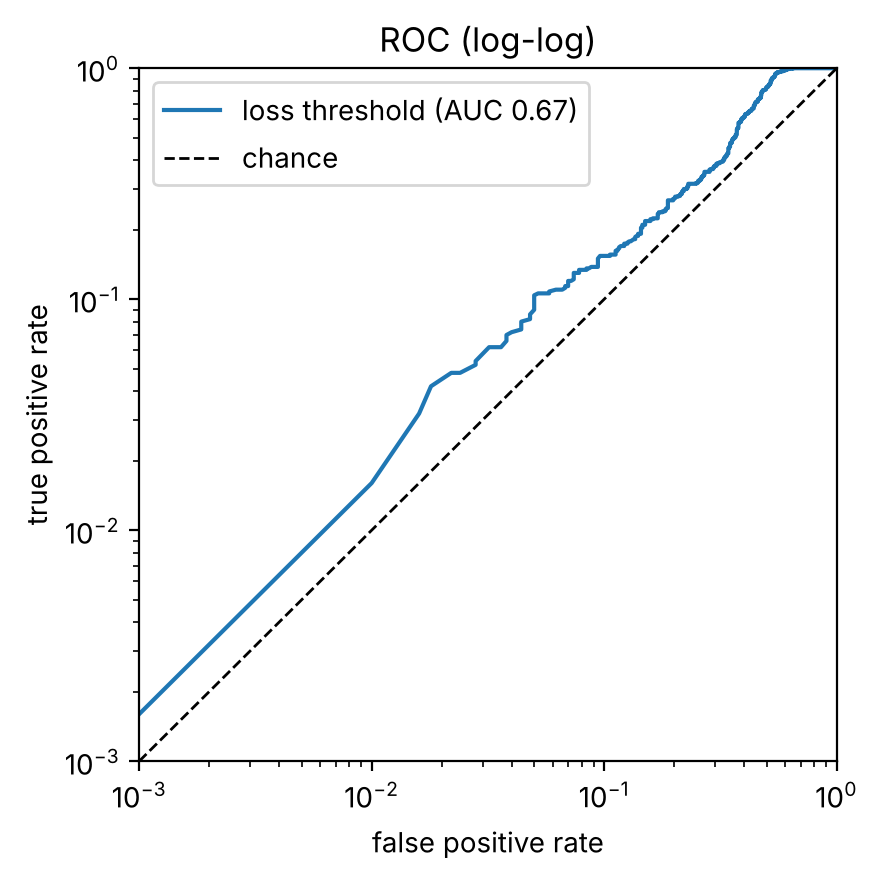

In [3]:
def evaluate_attack(score_mem, score_non, label, ax=None):
    # scores: higher = "more likely member"
    y_true = np.r_[np.ones(len(score_mem)), np.zeros(len(score_non))]
    s = np.r_[score_mem, score_non]
    fpr, tpr, _ = roc_curve(y_true, s); auc = roc_auc_score(y_true, s)
    tpr_at = lambda f: tpr[np.searchsorted(fpr, f, side="right") - 1]
    print(f"{label:38s} AUC = {auc:.3f}   TPR@1%FPR = {tpr_at(0.01):.3f}   TPR@0.1%FPR = {tpr_at(0.001):.3f}")
    if ax is not None: ax.plot(fpr, tpr, label=f"{label} (AUC {auc:.2f})")
    return auc

fig, ax = plt.subplots(figsize=(4.5, 4.5))
evaluate_attack(-loss_mem, -loss_non, "loss threshold", ax)
ax.plot([1e-3, 1], [1e-3, 1], "k--", lw=1, label="chance"); ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlim(1e-3, 1); ax.set_ylim(1e-3, 1); ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate"); ax.legend(); ax.set_title("ROC (log-log)")
plt.show()

## 4.3 Attack 2 — shadow models (Shokri et al., 2017)

The attacker does not know the victim's loss distribution — but can *simulate* it. Train several **shadow models** on your own data, mimicking the victim's training recipe; for each shadow you know exactly which samples were members. That gives labelled examples of "what a member's output looks like" vs "what a non-member's output looks like", on which an **attack classifier** is trained. Then apply it to the victim's outputs.

shadow 0: train acc 1.000  held-out acc 0.768


shadow 1: train acc 1.000  held-out acc 0.784


shadow 2: train acc 1.000  held-out acc 0.794


shadow 3: train acc 1.000  held-out acc 0.808


shadow 4: train acc 1.000  held-out acc 0.814


shadow 5: train acc 1.000  held-out acc 0.758


shadow 6: train acc 1.000  held-out acc 0.810


shadow 7: train acc 1.000  held-out acc 0.810


loss threshold                         AUC = 0.673   TPR@1%FPR = 0.016   TPR@0.1%FPR = 0.000
shadow-model attack                    AUC = 0.733   TPR@1%FPR = 0.036   TPR@0.1%FPR = 0.004


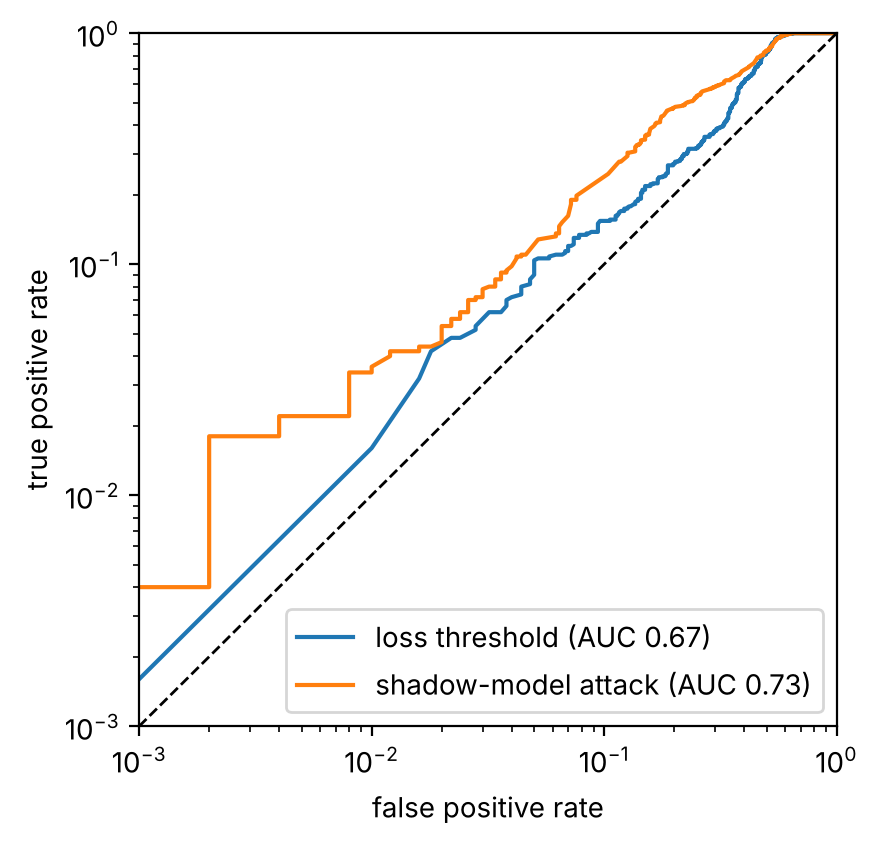

In [4]:
def attack_features(model, x, y):
    p = F.softmax(predict(model, x), dim=1)
    p_true = p[torch.arange(len(y)), y]
    p_sorted = p.sort(1, descending=True).values[:, :3]
    ent = -(p * (p + 1e-12).log()).sum(1)
    return torch.cat([p_true[:, None], p_sorted, ent[:, None], (-(p_true + 1e-12).log())[:, None]], 1).numpy()

N_SHADOW = 8
feats, labels = [], []
rng = np.random.default_rng(1)
for k in range(N_SHADOW):
    perm = rng.permutation(len(x_attacker))
    s_in, s_out = perm[:N_MEMBERS], perm[N_MEMBERS:2 * N_MEMBERS]
    shadow = victim_recipe(x_attacker[s_in], y_attacker[s_in], seed=100 + k)   # same recipe as the victim
    feats += [attack_features(shadow, x_attacker[s_in], y_attacker[s_in]), attack_features(shadow, x_attacker[s_out], y_attacker[s_out])]
    labels += [np.ones(N_MEMBERS), np.zeros(N_MEMBERS)]
    print(f"shadow {k}: train acc {accuracy(shadow, x_attacker[s_in], y_attacker[s_in]):.3f}  held-out acc {accuracy(shadow, x_attacker[s_out], y_attacker[s_out]):.3f}")

attack_clf = GradientBoostingClassifier().fit(np.concatenate(feats), np.concatenate(labels))

score_mem = attack_clf.predict_proba(attack_features(victim, x_mem, y_mem))[:, 1]
score_non = attack_clf.predict_proba(attack_features(victim, x_non, y_non))[:, 1]
fig, ax = plt.subplots(figsize=(4.5, 4.5))
evaluate_attack(-loss_mem, -loss_non, "loss threshold", ax)
evaluate_attack(score_mem, score_non, "shadow-model attack", ax)
ax.plot([1e-3, 1], [1e-3, 1], "k--", lw=1); ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(1e-3, 1); ax.set_ylim(1e-3, 1)
ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate"); ax.legend(); plt.show()

Both attacks separate members from non-members *on average* (AUC well above 0.5) — but look at **TPR at 1% FPR**: close to zero. A global threshold cannot say "this sample is a member" with confidence, because some *non-members* are just easy (low loss) and some *members* are just hard.

## 4.4 Attack 3 — per-example calibration: LiRA (Carlini et al., 2022)

The fix is to ask the right question: not *"is this loss low?"* but *"is this loss low **for this particular example**?"* The shadow models tell us how confident a model that has **not** seen $x$ typically is on $x$: fit a Gaussian to the shadow confidences of $x$ (on the logit scale, $\phi = \log\frac{p}{1-p}$), then score the victim's confidence against it. This is the *offline* variant of the Likelihood Ratio Attack.

loss threshold                         AUC = 0.673   TPR@1%FPR = 0.016   TPR@0.1%FPR = 0.000
shadow-model attack                    AUC = 0.733   TPR@1%FPR = 0.036   TPR@0.1%FPR = 0.004
LiRA (offline, 8 shadows)              AUC = 0.711   TPR@1%FPR = 0.106   TPR@0.1%FPR = 0.038


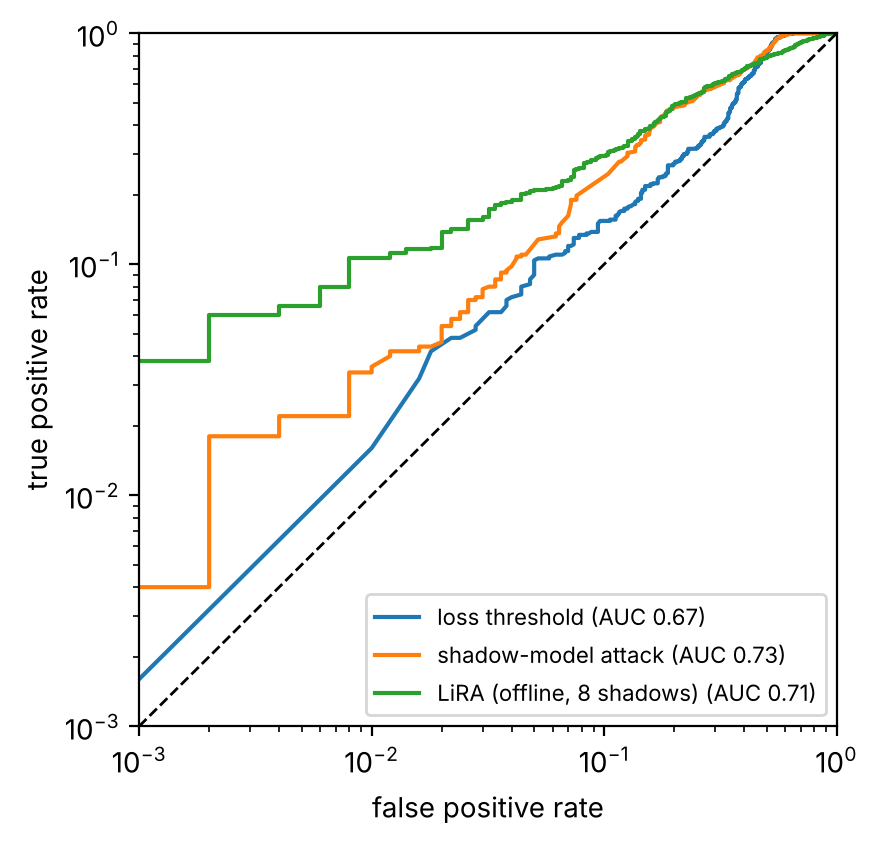

In [5]:
def logit_conf(model, x, y):
    p = F.softmax(predict(model, x), 1)[torch.arange(len(y)), y].numpy().astype(np.float64)
    p = np.clip(p, 1e-7, 1 - 1e-7); return np.log(p / (1 - p))

# shadow models trained on attacker data only -> every candidate (members and non-members of the victim) is OUT for every shadow
shadows = []
for k in range(N_SHADOW):
    sel = rng.permutation(len(x_attacker))[:N_MEMBERS]
    shadows.append(victim_recipe(x_attacker[sel], y_attacker[sel], seed=200 + k))

x_cand, y_cand = torch.cat([x_mem, x_non]), torch.cat([y_mem, y_non])
phi_out = np.stack([logit_conf(sh, x_cand, y_cand) for sh in shadows])      # (N_SHADOW, 2*N_MEMBERS)
mu_out, sd_out = phi_out.mean(0), phi_out.std(0).mean() + 1e-3            # per-example mean, global std (few shadows)
phi_victim = logit_conf(victim, x_cand, y_cand)
lira_score = norm.logcdf(phi_victim, loc=mu_out, scale=sd_out)             # how unusually confident is the victim on x, given x is hard/easy?

fig, ax = plt.subplots(figsize=(4.5, 4.5))
evaluate_attack(-loss_mem, -loss_non, "loss threshold", ax)
evaluate_attack(score_mem, score_non, "shadow-model attack", ax)
evaluate_attack(lira_score[:N_MEMBERS], lira_score[N_MEMBERS:], "LiRA (offline, 8 shadows)", ax)
ax.plot([1e-3, 1], [1e-3, 1], "k--", lw=1); ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(1e-3, 1); ax.set_ylim(1e-3, 1)
ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate"); ax.legend(fontsize=8); plt.show()

Same victim, same queries — but now the attacker confidently identifies a meaningful fraction of members at a 1% (even 0.1%) false-positive rate. The difference is entirely in **calibrating per example**, and it is why average-case metrics (AUC, accuracy) understate privacy risk.

## 4.5 Defense: don't overfit (early stopping, more data, regularisation)

MIA feeds on the generalisation gap. Let's shrink it with early stopping and with more data, and re-run the attacks each time (loss threshold and LiRA). (Weight decay is left as an exercise — with Adam it barely changes the gap here.)

overfit (500 samples, 100 epochs)              test acc = 0.778   gap = +0.222
   loss threshold                      AUC = 0.673   TPR@1%FPR = 0.016   TPR@0.1%FPR = 0.000
   LiRA                                AUC = 0.711   TPR@1%FPR = 0.106   TPR@0.1%FPR = 0.038
early stop (500 samples, 15 epochs)            test acc = 0.756   gap = +0.104
   loss threshold                      AUC = 0.586   TPR@1%FPR = 0.034   TPR@0.1%FPR = 0.010
   LiRA                                AUC = 0.518   TPR@1%FPR = 0.026   TPR@0.1%FPR = 0.006


more data (18k samples, 5 epochs)              test acc = 0.850   gap = +0.034
   loss threshold                      AUC = 0.532   TPR@1%FPR = 0.004   TPR@0.1%FPR = 0.000
   LiRA                                AUC = 0.490   TPR@1%FPR = 0.024   TPR@0.1%FPR = 0.002


more data, long (18k samples, 30 epochs)       test acc = 0.862   gap = +0.088
   loss threshold                      AUC = 0.550   TPR@1%FPR = 0.000   TPR@0.1%FPR = 0.000
   LiRA                                AUC = 0.561   TPR@1%FPR = 0.010   TPR@0.1%FPR = 0.004


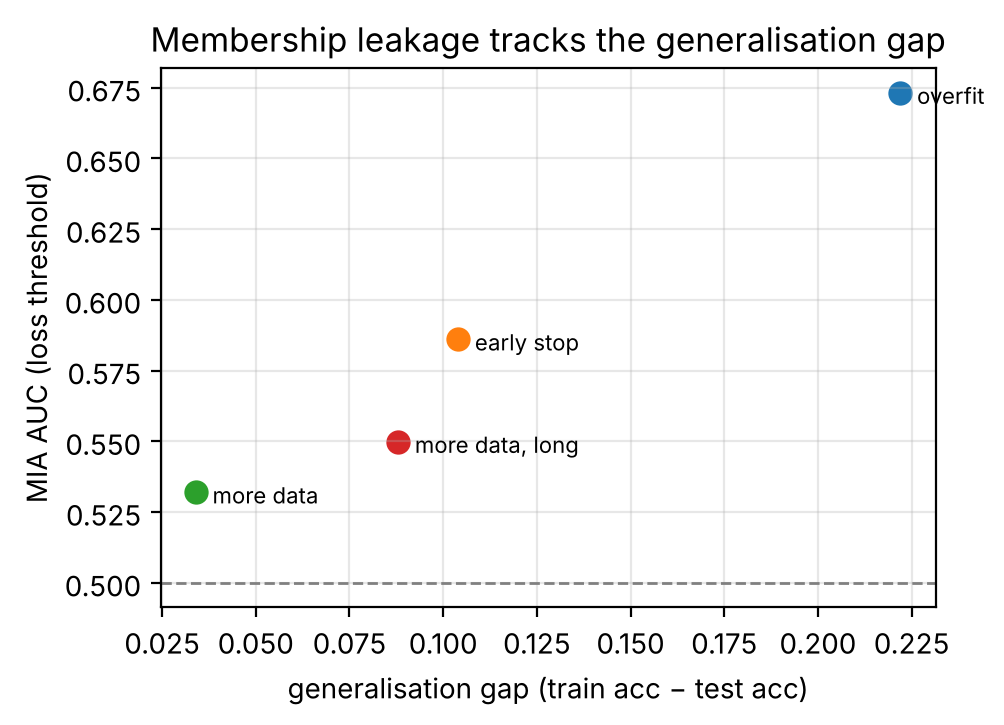

In [6]:
configs = {
    "overfit (500 samples, 100 epochs)":       dict(n=500,    epochs=100),
    "early stop (500 samples, 15 epochs)":     dict(n=500,    epochs=15),
    "more data (18k samples, 5 epochs)":       dict(n=18_000, epochs=5),
    "more data, long (18k samples, 30 epochs)": dict(n=18_000, epochs=30),
}
rows = []
for name, c in configs.items():
    seed_everything(0)
    m = train(MLP(), x_all[:c["n"]], y_all[:c["n"]], epochs=c["epochs"], verbose=False)
    gap = accuracy(m, x_mem, y_mem) - accuracy(m, x_non, y_non)            # evaluate MIA on the same 500 members in every case
    print(f"{name:46s} test acc = {accuracy(m, x_non, y_non):.3f}   gap = {gap:+.3f}")
    auc = evaluate_attack(-per_sample_loss(m, x_mem, y_mem), -per_sample_loss(m, x_non, y_non), "   loss threshold")
    sc = norm.logcdf(logit_conf(m, x_cand, y_cand), loc=mu_out, scale=sd_out)   # LiRA with the *overfit-recipe* shadows (mismatched for the defended models)
    evaluate_attack(sc[:N_MEMBERS], sc[N_MEMBERS:], "   LiRA")
    rows.append((name, gap, auc))

plt.figure(figsize=(5, 3.5))
for name, gap, auc in rows:
    plt.scatter(gap, auc, s=60); plt.annotate(name.split("(")[0].strip(), (gap, auc), textcoords="offset points", xytext=(6, -4), fontsize=8)
plt.axhline(0.5, ls="--", c="gray", lw=1); plt.xlabel("generalisation gap (train acc − test acc)"); plt.ylabel("MIA AUC (loss threshold)")
plt.title("Membership leakage tracks the generalisation gap"); plt.grid(alpha=.3); plt.show()

Closing the gap brings the attack back toward chance — on *average*. Two caveats the class should hear:

* Even a well-generalising model can leak **a few** memorised outliers (rare, mislabelled or duplicated samples); average-case AUC hides this, which is why TPR at low FPR is reported. (LiRA above was run with shadows that mimic the *overfit* recipe; a careful attacker would re-train shadows to match each defended model.)
* The only defense with a *guarantee* is **differential privacy** (DP-SGD: clip per-example gradients, add noise): it bounds how much any single record can change the model — and therefore any MIA's advantage — at a cost in accuracy and compute.

## Take-aways

* Models **remember** their training data; confidence scores leak membership.
* The attack needs only black-box access; shadow models let the attacker calibrate it — **per example** (LiRA) is what makes it precise at low FPR.
* **Overfitting is a security vulnerability**, not just a modelling flaw; regularisation and more data mitigate, DP-SGD bounds.
* Report **TPR at low FPR**, not just AUC — privacy is about the worst case.

### References
* Shokri, Stronati, Song, Shmatikov, *Membership Inference Attacks Against Machine Learning Models*, IEEE S&P 2017.
* Yeom et al., *Privacy Risk in Machine Learning: Analyzing the Connection to Overfitting*, CSF 2018.
* Carlini et al., *Membership Inference Attacks From First Principles* (LiRA), IEEE S&P 2022.
* Abadi et al., *Deep Learning with Differential Privacy* (DP-SGD), CCS 2016.